# Tutorial – Passo 3: Trabalhando com a qualidade dos dados

Neste tutorial, veremos como as informações sobre a qualidade dos dados são armazenadas nos arquivos de dados do GWOSC.
Se você ainda não se sente à vontade para usar Python para ler um arquivo de dados do GWOSC, talvez queira dar uma olhada em [Passo 2 deste tutorial](<02 - What's in a GWOSC Data File.ipynb>).

<div class="alert alert-block alert-warning">
<div><b>&#9888; Warning</b></div>
   Remova o comentário da célula a seguir se estiver executando no Google Colab. 
Se utilizar outros métodos de execução, isso não deve ser necessário.
</div>

In [1]:
#! wget http://gwosc.org/archive/data/O3b_4KHZ_R1/1263534080/H-H1_GWOSC_O3b_4KHZ_R1-1264312320-4096.hdf5

## O que é qualidade de dados?

Além da principal saída de dados dos detectores LIGO (o canal de *strain*), existem centenas de outros canais de dados registrados para monitorar o estado tanto dos instrumentos quanto do ambiente externo.
Alguns desses canais auxiliares são utilizados para criar indicadores de qualidade de dados, assinalando momentos em que os dados de *strain* provavelmente estão corrompidos por artefatos instrumentais.

<div class="alert alert-block alert-warning">
<div><b>&#9888; Warning: Compreender a qualidade dos dados é muito importante ao trabalhar com dados do GWOSC.</b></div>
Antes de realizar qualquer análise, utilize este tutorial e a <a href="https://gwosc.org/data">documentação dos dados</a> para identificar os intervalos de tempo adequados para a sua análise.
</div>

<div class="alert alert-block alert-warning">
<div><b>&#9888; Warning</b></div>
   Os tempos que falham na flag da categoria DATA são representados por NaNs e nunca devem ser analisados. 
   Os tempos que falham em qualquer flag de nível CAT1 apresentam problemas graves e também não devem ser pesquisados em fontes astrofísicas.
</div>

As flags de qualidade dos dados são organizadas em categorias com base na gravidade do impacto que podem ter sobre um determinado tipo de busca.
As categorias para cada tipo de busca são definidas de maneiras distintas, mas, de modo geral, uma categoria de qualidade de dados mais baixa indica um problema mais grave.
Assim, por exemplo, uma flag de Categoria 1 para CBC significa que um trecho de dados está fortemente corrompido e não pode ser utilizado para buscar sinais de coalescência de binárias compactas (CBC) de baixa massa, ao passo que uma flag de Categoria 3 para CBC indica um problema menos significativo nos dados.

Para uma explicação mais detalhada do significado das várias flags, consulte o [data documentation](https://gwosc.org/data).

## Como as informações sobre a qualidade dos dados são armazenadas?

As informações de qualidade dos dados são armazenadas em arquivos de dados GWOSC como uma série temporal de 1 Hz para cada categoria.
Observe que esta é uma taxa de amostragem diferente da taxa de 4096 Hz usada para armazenar dados de deformação.
Assim, por exemplo, a primeira amostra em um canal de qualidade de dados se aplica às primeiras 4.096 amostras no canal de deformação correspondente.

No conjunto de dados O3b, existem 7 categorias de qualidade de dados, bem como 5 categorias de injeção, cada uma representada como uma série temporal de 1 Hz.
Vamos exibir uma lista dos nomes e descrições dos canais de qualidade de dados do O3b a partir do arquivo de dados.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py

filename = 'H-H1_GWOSC_O3b_4KHZ_R1-1264312320-4096.hdf5'
dataFile = h5py.File(filename, 'r')
gpsStart = dataFile['meta']['GPSstart'][()]

dqInfo = dataFile['quality']['simple']
bitnameList = dqInfo['DQShortnames'][()]
descriptionList = dqInfo['DQDescriptions'][()]
nbits = len(bitnameList)

for bit in range(nbits):
    print(f"Channel #{bit} ({bitnameList[bit].decode()}): {descriptionList[bit].decode()}")

Channel #0 (DATA): data present
Channel #1 (CBC_CAT1): passes the cbc CAT1 test
Channel #2 (CBC_CAT2): passes cbc CAT2 test
Channel #3 (CBC_CAT3): passes cbc CAT3 test
Channel #4 (BURST_CAT1): passes burst CAT1 test
Channel #5 (BURST_CAT2): passes burst CAT2 test
Channel #6 (BURST_CAT3): passes burst CAT3 test


Todas as categorias de qualidade de dados são combinadas e armazenadas como um array de 4096 entradas (uma entrada para cada segundo de dados). No arquivo de dados, isso é chamado de `DQmask`.
Você pode extraí-lo do arquivo de dados utilizando este código:

In [2]:
dqmask = dqInfo['DQmask'][()]

Cada amostra nesta matriz codifica todas as 7 categorias de qualidade de dados como um número inteiro.
Como você sabe, os números inteiros são representados em binário na memória do computador (se você não estiver familiarizado com números binários, consulte [esta página](https://en.wikipedia.org/wiki/Binary_number#Counting_in_binary)).
Para explicar como as categorias são representadas, vamos pegar um exemplo e imprimi-lo como um número binário de 7 dígitos.

In [3]:
value = dqmask[2400]
print("Value in decimal: {0}".format(value))
print("Same value in binary (with 7 bits): {0:#09b}".format(value))
# As python prefixes binary numbers with "0b", we have to ask for 9 characters to get the 7 bits

Value in decimal: 31
Same value in binary (with 7 bits): 0b0011111


Assim, o valor 31 é representado em binário como `0 011 111` (para maior clareza, apresentamos os bits em grupos de 3 e descartamos o prefixo `0b` utilizado no Python).

Nesta representação, o primeiro bit (começando pela direita) representa o primeiro canal da lista acima (`DATA`);
o segundo corresponde ao segundo canal (`CBC_CAT1`), etc. (veja abaixo).

![bits](./img/bits.png)

Observe que as posições dos bits e os números dos canais começam em 0.

Um dígito "1" em uma posição específica significa que a flag correspondente está ativa, indicando que os dados são "bons" naquele nível de categoria; já um dígito "0" significa que a flag está desativada, indicando que os dados são "ruins" naquele nível de categoria.

Assim, no exemplo, um valor de DQmask igual a `0 011 111` significa que:
- os dados do detector estão disponíveis (porque o bit na posição 0 é 1)
- os dados atendem aos critérios `CBC_CAT1`, `CBC_CAT2`, `CBC_CAT3` e `BURST_CAT1` (já que os bits nas posições 1 a 4 são 1), mas não cumprem as demais condições de qualidade dos dados

Essa representação é chamada de máscara de bits.
Essa é uma maneira compacta de armazenar uma grande quantidade de informações, mas, para trabalhar com a qualidade dos dados, precisaremos colocá-las em um formato mais conveniente.
Vamos tentar desmembrar algumas dessas informações sobre a qualidade dos dados.

## Utilizando informações sobre a qualidade dos dados

Na maioria dos casos, você não vai querer acompanhar todas as categorias de qualidade de dados, mas apenas alguns valores importantes para a sua busca.
Por exemplo, para buscar fontes de ondas gravitacionais transientes, como supernovas ou fusões de objetos compactos, você pode querer acompanhar a categoria DATA, bem como todas as categorias BURST.

Para isso, manipularemos a representação binária usando duas operações:
- $b \gg n$, que desloca os bits de $b$ para a direita $n$ vezes (isto é, descarta os primeiros $n$ bits); 
Por exemplo, `0 011 111 >> 2` resultaria em `0 000 111`. 
Observe que $n=0$ deixa $b$ inalterado. 
- $a \; \& \; b$, que realiza uma operação lógica AND bit a bit. 
Por exemplo, `0 011 111 & 1 000 101` resultaria em `0 000 101`.

Suponha que desloquemos um número de 7 bits. $b_6 \quad b_5 b_4 b_3 \quad b_2 b_1 b_0$, 3 vezes para a direita: isso significa que o bit que estava na posição 3 agora está na posição 0:
$$
 0 \quad 0 0 b_6 \quad b_5 b_4 b_3
$$

Agora, lembre-se de que o 1 é sempre codificado. `0 000 001`.
Portanto, se realizarmos uma operação AND bit a bit entre o valor deslocado e 1, obteremos:
$$
\begin{matrix}
        & 0\quad & 0 & 0 & b_6\quad & b_5 & b_4 & b_3 \\
\&\quad & 0\quad & 0 & 0 & 0\quad   &   0 &   0 &   1
\end{matrix}
$$

É fácil perceber que isso será sempre igual a $b_3$.
Portanto, para obter o valor da categoria no canal 3, primeiro deslocamos o valor de DQmask 3 posições para a direita e, em seguida, realizamos uma operação AND bit a bit entre esse resultado e o valor 1.

É fácil generalizar isso.
Então, para detalhar apenas as categorias `BURST_CAT2` (bit 5) e `DATA` (bit 0), podemos proceder da seguinte forma:

In [4]:
data_channel = 0
data_mask = (dqmask >> data_channel) & 1

burst_cat2_channel = 5
burst_cat2_mask = (dqmask >> burst_cat2_channel) & 1

Agora, a variável `data_mask` será 0 onde quer que os dados não atendam à categoria `DATA`, e 1 onde quer que atendam a essa categoria.
Da mesma forma, como `BURST_CAT2` está armazenado no bit 5, a variável `burst_cat2_mask` corresponderá a essa categoria.

Em um caso típico, você deseja utilizar apenas dados em que todas as categorias de interesse tenham sido aprovadas ("passed"), indicando dados relativamente limpos.
Para isso, basta realizar a operação lógica E (AND) elemento a elemento entre todos os canais necessários:

In [5]:
goodData_mask_1hz = data_mask & burst_cat2_mask

Para confirmar que `goodData_mask_1hz` está ativo quando ambas as categorias `DATA` e `BURST_CAT2` são fornecidas, podemos gerar um gráfico desses três canais de DQ.

Text(0.5, 0, 'Time (s)')

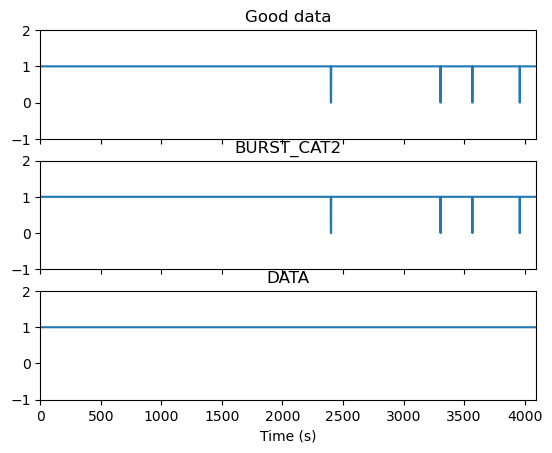

In [6]:
fig, (ax0, ax1, ax2) = plt.subplots(3, sharex=True, sharey=True)
ax0.plot(goodData_mask_1hz)
ax0.set_title('Good data')
ax1.plot(burst_cat2_mask)
ax1.set_title('BURST_CAT2')
ax2.plot(data_mask)
ax2.set_title('DATA')
ax2.axis([0, 4096, -1, 2])
ax2.set_xlabel('Time (s)')

Aqui estão alguns pontos a observar no gráfico:
- O valor 1 indica que a categoria foi aprovada; portanto, aquele segundo de dados é adequado para uso na sua análise. 
- Neste exemplo, `goodData_mask_1hz` é o resultado da operação lógica AND entre os outros dois. 
- A flag `BURST_CAT2` assume o valor 0 por curtos intervalos de tempo. Assim, existem vários segmentos de "dados válidos" neste arquivo.

Uma maneira conveniente de ignorar períodos de dados ruins é utilizar segmentos de qualidade de dados na forma de uma lista de fatias (*slices*) do Python. Eles podem ser obtidos da seguinte maneira:

In [7]:
dummy = np.zeros(goodData_mask_1hz.shape)
masked_dummy = np.ma.masked_array(dummy, np.logical_not(goodData_mask_1hz) )
segments = np.ma.flatnotmasked_contiguous(masked_dummy)
segList = [(int(seg.start+gpsStart), int(seg.stop+gpsStart)) for seg in segments]
print(segList)

[(1264312320, 1264314720), (1264314723, 1264315625), (1264315628, 1264315888), (1264315891, 1264316279), (1264316282, 1264316416)]


Agora podemos traçar os primeiros segundos de cada segmento.

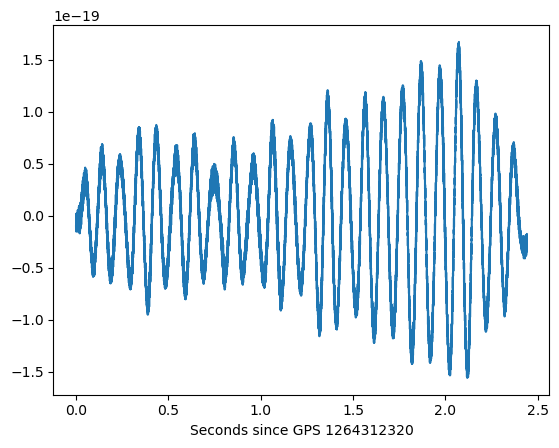

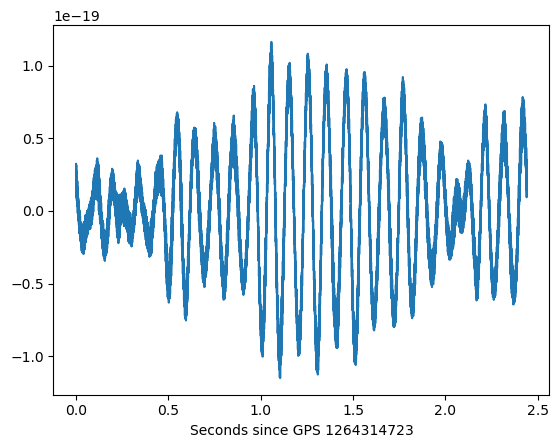

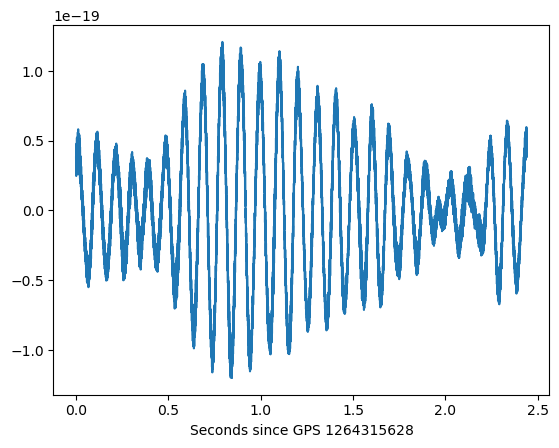

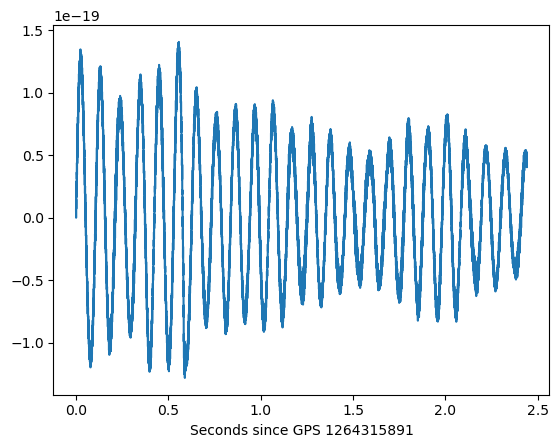

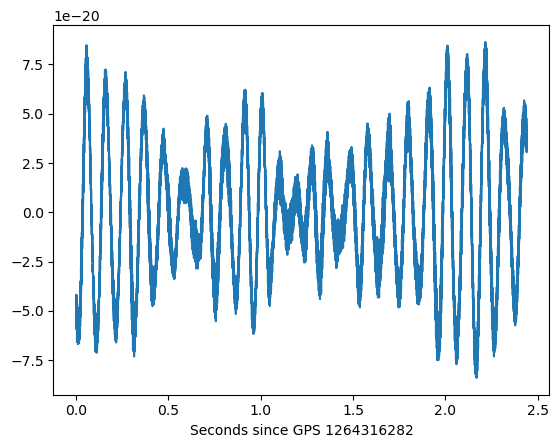

In [8]:
N      = 10000
strain = dataFile['strain']['Strain']
dt     = dataFile['strain']['Strain'].attrs['Xspacing']
for (begin, end) in segList:
    plt.figure()
    rel_time = np.arange(0, end - begin, dt)
    # Convert begin and end to indices
    index_begin = int((begin - gpsStart) / dt)
    index_end   = int((end - gpsStart) / dt)
    seg_strain = strain[index_begin:index_end]
    # Plot N values
    plt.plot(rel_time[0:N], seg_strain[0:N])
    plt.xlabel('Seconds since GPS ' + str(begin) )

## Qual é o próximo passo?

O [próximo passo](<04 - Working in the Frequency Domain.ipynb>) apresentará alguns conceitos importantes para trabalhar com dados de ondas gravitacionais.